In [24]:
#importing required libraries
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm
from scipy.optimize import curve_fit

In [25]:
#assigning given values to the parameters
alpha = -300e6 #anharmonicity
t_g = 20e-9    #gate duration
T1 = 100e-6    #T1
T2 = 80e-6     #T2
T_rep = 500e-6 #Repetition time per shot
seed = 2026    # seed provided
T_sim = 24     #simulation over 24hrs
Threshold_error=1e-3 # threshold ie; minmum error


In [26]:
#defining dirac notation for the 3 level transmon to make things easy
def dirac_notation(n):
  basis = np.zeros((3,1), dtype=int)
  basis[n,0]=1
  return basis

In [27]:
ket0 = dirac_notation(0)
ket1 = dirac_notation(1)
ket2 = dirac_notation(2)
#made shortcut notations for transition states

In [28]:
"""defining the anhillation and creation operators for a 3 level transmon which are found by taking 
a |n> = sqrt(n) |n-1>. a_dagger |n> = sqrt(n+1) |n+1>"""

'defining the anhillation and creation operators for a 3 level transmon which are found by taking \na |n> = sqrt(n) |n-1>. a_dagger |n> = sqrt(n+1) |n+1>'

In [29]:
def make_operators():
  """Returns
  a - anhillation operator
  a_dagger - creation operator"""
  a = np.array([[0,1,0],
               [0,0,np.sqrt(2)],
               [0,0,0]])
  a_dagger = np.array([[0, 0, 0],
                      [1, 0, 0],
                      [0, np.sqrt(2), 0]])
 #I found the matrix of these operators by solving the simultaneous equations of matrices on paper
  return a, a_dagger

In [30]:
def hamiltonian(delta, g, ox, oy,alpha,a_dagger,a):
  """Parameters
  delta : drifting detuning  wrt time
  g: drifting drive gain
  ox: X-quadrature amplitude (pulse given to produce X-axis rotation)
  oy : Y-quadrature amplitude (pulse given to produce Y-axis rotation)
  alpha : anharmonicity
  a : annihilation operator
  a_dagger : creation operator
  Returns
  result : hamiltonian"""
  result = delta*(a_dagger@a)+(alpha/2)*(a_dagger@a_dagger@a@a)+(g/2)*(ox*(a+a_dagger)+oy*1j*(a_dagger-a))
  return result

In [31]:
def gaussian_pulse(theta, beta, n_steps):
  """Parameters
  theta : rotation angle
  beta : DRAG coefficient
  n_steps:no.of small intervals the time is taken

  returns
  ox : an array of X-quadrature amplitude
  oy : an array of Y-quadrature amplitude"""
  dt = t_g/n_steps
  #time in one small interval
  t0 = t_g/2
  #time center
  sigma = t_g/4
  #pulse width given in problem statement
  #there should be arrays of time stamps and
  t = np.zeros(n_steps)
  #now let's assign the equation exp(-(t-t0)^2/(2*sigma^2)) to bell
  bell = np.zeros(n_steps)
  for i in range(n_steps):
    t[i] = i*dt
    bell[i] = np.exp(-(t[i]-t0)**2/(2*sigma**2))
  """To find A as integral ox over dt = theta
  A*integral of bell over dt = theta
  A = theta/integral of bell over dt"""
  integral = 0
  for i in range(n_steps):
    k = bell[i]*dt
    integral += k
  A = theta/integral
  ox = A*np.exp(-(t-t0)**2/(2*sigma**2))
  #X-quadrature amplitude is obtained
  #now to find differential of ox over time
  d_ox = np.gradient(ox, dt)
  #gives the derivative of ox over given spacing between time stamps dt
  oy = -beta*d_ox
  return ox, oy

ox,oy = gaussian_pulse(np.pi/2, 0.5, 10)
print('ox:', ox)
print('oy:', oy)

ox: [1.78239390e+07 3.66180923e+07 6.41062871e+07 9.56353424e+07
 1.21576348e+08 1.31702085e+08 1.21576348e+08 9.56353424e+07
 6.41062871e+07 3.66180923e+07]
oy: [-4.69853831e+15 -5.78529351e+15 -7.37715627e+15 -7.18375758e+15
 -4.50834286e+15  3.72529030e+00  4.50834286e+15  7.18375758e+15
  7.37715627e+15  6.87204872e+15]


In [32]:
def propagator(delta, g, ox, oy, alpha, a, a_dagger):
  """Parameters
  delta : detuning drift
  g : drift gain
  ox : X-quadrature amplitude (array)
  oy : Y-quadrature amplitude (array)
  alpha : anharmonicity
  a : annihilation operator
  a_dagger : creation operator
  Returns
  U : propagator"""
  n = len(ox) #n is equivalent to n_steps size of the array
  #taking the size of array ox

  U = np.zeros((n,3,3),dtype=complex)
  dt = t_g/n
  for i in range(n):
    U[i] = expm(-1j*hamiltonian(delta, g, ox[i], oy[i], alpha, a_dagger, a)*dt)

  U_res = np.eye((3), dtype=complex)
  for i in range(n):
    U_res = U[i]@U_res #the order of multiplication of matrices should be U_last....U1
  return U_res





In [33]:
def gate_error(U, V_target):
  M = U[:2,:2] # taking the upper 2×2 matrice of the obtained propagator of 3 level transmon
  V_dagger = np.conjugate(np.transpose(V_target)) 
  M_v = V_dagger@M
  M_v_dagger = np.conjugate(np.transpose(M_v))
  F = (np.trace(M_v@M_v_dagger)+np.abs((np.trace(M_v)))**2)/6
  eps = 1-F
  return eps

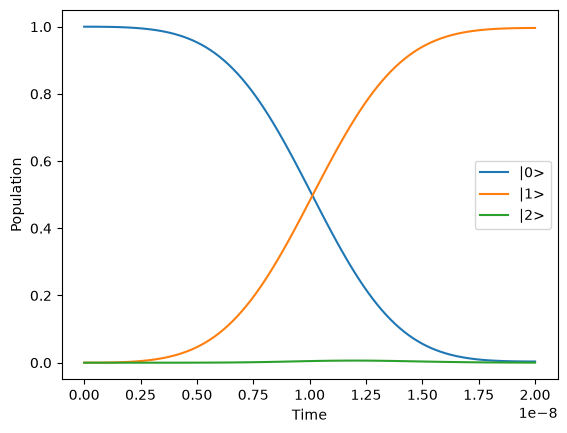

(0.0025381189134283666+0j)


In [34]:
# checking the plant model

a = make_operators()[0]
a_dagger = make_operators()[1]
delta = 0
g = 1
n = 100
w = alpha*2*np.pi #hamiltonian alpha is in rad/s but here we defined in Hz
ox = gaussian_pulse(np.pi, 0, n)[0]
oy = gaussian_pulse(np.pi, 0, n)[1]

dt = t_g / n

U = np.zeros((n, 3, 3), dtype=complex)

for i in range(n):
    H_step = hamiltonian(delta, g, ox[i], oy[i], w, a_dagger, a)
    U[i] = expm(-1j * H_step * dt)

psi = np.array([
    [1],
    [0],
    [0]
], dtype=complex)

p0 = []
p1 = []
p2 = []

# initial state: t = 0
p0.append(np.abs(psi[0,0])**2)
p1.append(np.abs(psi[1,0])**2)
p2.append(np.abs(psi[2,0])**2)

# evolution
for i in range(n):
    psi = U[i] @ psi

    p0.append(np.abs(psi[0,0])**2)
    p1.append(np.abs(psi[1,0])**2)
    p2.append(np.abs(psi[2,0])**2)

# time array
t = np.zeros(n + 1)

for i in range(n + 1):
    t[i] = i * dt

# plot
plt.plot(t, p0, label='|0>')
plt.plot(t, p1, label='|1>')
plt.plot(t, p2, label='|2>')

plt.xlabel("Time")
plt.ylabel("Population")
plt.legend()
plt.show()
U_res = np.eye((3), dtype=complex)
for i in range(100):
   U_res = U[i]@U_res
V_target = np.array([[0, 1], [1, 0]], dtype=complex) #X gate
eps = gate_error(U_res, V_target )
print(eps)

In [35]:
rng = np.random.default_rng(2026)

#define a function to find populations
def populations(U):
  psi = U[:, 0]
  p = np.abs(psi)**2
  return p[0], p[1], p[2]

#now to take the probabilities over shots
def prob_shots(p0,p1,p2, n_shots,rng):
  #P(1|0) = 1%, P(0|1) = 3%; |2⟩ reads as 1
  #given readout error
  p_read1 = 0.01*p0 + 0.97*p1 + 1.00*p2
  p_read1 = np.clip(p_read1, 0.0, 1.0) #to gaurd against clipping
  ones = rng.binomial(n_shots, p_read1)
  return ones, n_shots

In [36]:
# Error amplification function
def error_amplification(n,p0,p1):
    ''' Parameters:
    n : number of shots,
    p0 : population of |0> state,
    p1 : population of |1> state,'''
    pi = np.pi
    # Calculation of the <Z> expectation value:

    Z_expectation = (p0 - p1) # Assuming |0> --> +1 and |1> --> -1 in Z-axis

    # Calculation of the eta factor with z_expectation:

    eta = -((-1)**n)*Z_expectation/(n*pi)

    return eta

In [37]:
# Detuning estimation function
def detuning_estimation(tau, delta, n, T2, phi0):
    '''Parameters:
    tau : array of delay times
    delta : estimated detuning
    n : number of shots
    T2 : coherence time
    phi0 : initial phase'''

    # Defining the visibility 
    V  = np.exp(-tau / T2)
    # Calculate the ideal probabilities for |0> state:
    P0_ideal = 0.5 * (1 + V * np.cos(2*np.pi*delta * tau + phi0))

    # Simulating variance measurement with Cram´er–Rao bound method
    variance = 1 / (n * (2 * np.pi * tau * V) ** 2)

    delta_c = np.sqrt(variance)  # Calculate detuning error

    return delta_c, P0_ideal


In [38]:

def drag_calibration(beta,n_steps,n_pairs_values,delta,g,alpha,a,a_dagger):
    """
    Perform DRAG calibration for one beta value.

    beta          : DRAG coefficient
    n_steps       : time samples used to construct each pulse
    n_pairs_values: number of identity-pair repetitions to test
    delta         : detuning
    g             : drive gain
    alpha         : transmon anharmonicity
    a             : annihilation operator
    a_dagger      : creation operator
    """

    # Generate the +pi DRAG pulse
    ox1, oy1 = gaussian_pulse(np.pi, beta, n_steps)

    # Calculate the propagator for the +pi pulse
    U1 = propagator(
        delta, g, ox1, oy1, alpha, a, a_dagger
    )

    # Generate the -pi DRAG pulse
    ox2, oy2 = gaussian_pulse(-np.pi, beta, n_steps)

    # Calculate the propagator for the -pi pulse
    U2 = propagator(
        delta, g, ox2, oy2, alpha, a, a_dagger
    )

    # One identity pair:
    # First +pi, then -pi
    U_pair = U2 @ U1

    # Store the measured/simulated probabilities
    p0_data = []
    p1_data = []
    p2_data = []

    # Test different numbers of identity pairs
    for n_pairs in n_pairs_values:

        # Start with no pulses: identity evolution
        U_total = np.eye(3, dtype=complex)

        # Repeat the identity pair n_pairs times
        for _ in range(n_pairs):
            U_total = U_pair @ U_total

        # Calculate final populations
        p0, p1, p2 = populations(U_total)

        p0_data.append(p0)
        p1_data.append(p1)
        p2_data.append(p2)

    # Convert lists to NumPy arrays
    n = np.asarray(n_pairs_values, dtype=float)
    p0_data = np.asarray(p0_data)
    p1_data = np.asarray(p1_data)
    p2_data = np.asarray(p2_data)

    # Fit P(1) against the number of identity pairs
    slope, intercept = np.polyfit(n, p1_data, 1)

    return {
        "beta": beta,
        "n_pairs": n,
        "p0": p0_data,
        "p1": p1_data,
        "p2": p2_data,
        "slope": slope,
        "intercept": intercept
    }


In [39]:
def detuning_estimation(tau, delta, n, T2, phi0):
    '''Parameters:
    tau : array of delay times
    delta : estimated detuning
    n : number of shots
    T2 : coherence time
    phi0 : initial phase'''

    # Defining the visibility
    V  = np.exp(-tau / T2)
    # Calculate the ideal probabilities for |0> state:
    P0_ideal = 0.5 * (1 + V * np.cos(2*np.pi*delta * tau + phi0))

    # Simulating variance measurement with Cram´er–Rao bound method
    variance = 1 / (n * (2 * np.pi * tau * V) ** 2)

    delta_c = np.sqrt(variance)  # Calculate detuning error

    return delta_c, P0_ideal

In [40]:
def error_amplification(n,p0,p1):
    ''' Parameters:
    n : number of shots,
    p0 : population of |0> state,
    p1 : population of |1> state,'''
    pi = np.pi
    # Estimate the amplification error based on the number of shots and populations:
    # Calculate the <Z> expectation value:

    Z_expectation = (p0 - p1) # Assuming |0> --> +1 and |1> --> -1 in Z-axis

    # Calculation of the eta factor with z_expectation:

    eta = -((-1)**n)*Z_expectation/(n*pi) #n*pi*eta is a very small value for smaller values sin can be neglected

    return eta

In [41]:
def ou_drift(n, dt, sigma, tau_c, rng, mue):
  """Parameters
  n : the number of time steps in the day
  dt : Time between points, in seconds
  sigma : standard deviation
  tau_c : correlation time
  mue :  average value
  Returns
  slow frequency drift"""
  x = np.zeros(n)
  #initializing the array to zeros
  x[0] = mue + sigma*rng.standard_normal() # to set an initial value for x based on which next values are found
  #rng.standard_normal() draws one random number, typically between -2 and +2 (mostly near 0).
  #Multiplying by sigma scales it to the right size. For frequency, that gives a typical starting drift of about ±150 kHz.
  a =  np.exp(-dt / tau_c)
  b =  sigma * np.sqrt(1 - a**2)
  for k in range(n - 1):
        x[k+1] = mue + (x[k] - mue) * a + b * rng.standard_normal()
  return x


In [42]:
def telegraph_noise(n, dt, mean_dwell, rng):
  """Parameters
  n : the number of time steps in a day
  dt : Time between points, in seconds
  mean_dwell : the average time the signal stays before flipping
  rng : random number generator
  Returns
  random teligraph noise switching between 0 and 0.8MHz"""
  #it switches between 0 and 0.8MHz with, exponential dwell times
  p_switch = 1-np.exp(-dt/mean_dwell) #probability of change in state of teligraph noise in a time dt
  state = rng.integers(0, 2) #used to give a random output either 0 or 1
  J_out = np.zeros(n)
  for k in range(n):
    J_out[k] = 0.8e6*state #0.8MHz is switching level mentioned in the problem statement
    if rng.random() < p_switch:
            state = 1 - state
  #switches the state of teligraph randomly
  return J_out


In [43]:
def drift(dt, day=24*60*60,hr=60*60, seed=2026):
  """Parameters
  seed : seed given to maintain uniformity
  Returns
  drift in frequency and gain over time"""
  rng = np.random.default_rng(seed) #to generate random numbers for time varying
  t = np.arange(0, day+dt, dt) # creating time stamps
  n = len(t) # no.of time stamps
  # Detuning: Delta/2pi in Hz
  xf = ou_drift(n, dt, 150e3, 2*hr, rng,0) #slow frequency drift term
  J  = telegraph_noise(n, dt, 4*hr, rng)  #random teligraph noise
  delta_hz = xf + J
  #calculating gain drift
  xg = ou_drift(n, dt, sigma=0.005, tau_c = 3*3600,rng=rng, mue=0.0)
  phi = rng.uniform(0, 2*np.pi) #draws a random phi value from a uniform continues distribution
  gain = 1 + 0.02*np.sin((2*np.pi*t)/(day)+phi) + xg

  return delta_hz, gain, t

In [44]:
drift_est = drift(dt=10) #taken for 10s time intervals

In [45]:
def drift_t(t_now, drift_est):
  """Parameters
  t_now : time at this point
  drift_est : ouput of drift()
  Returns
  detuning and gain drift at t_now"""
  delta_hz = drift_est[0]
  gain = drift_est[1]
  t = drift_est[2]
  delta_rad = 2*np.pi*np.interp(t_now, t, delta_hz) #detuning is converted to rad/s
  #here interpolation is used as t_now can be a value not in the timestamp array
  g = np.interp(t_now, t, gain)
  return delta_rad, g
  # returns detuning and gain drift at any point of time t_now


In [46]:
#assuming initial conditions are idwal for an uncallibrated system
alpha_w = 2*np.pi*(-300e6)
ini = {
    "df" : 0.0,            #assumed initial detuning frequency
    "amp" : 1.0,           #pulse amplitude scale factor
    "beta" : 1/abs(alpha_w) # Drag start value
}

In [47]:
#defining the shot time per calibration
shot_time = 500e-6
clock = {
    "t" : 0.0,
    "calib_time" : 0.0
}
#taking current time in day day and total time spent on calibration in a dictionary


In [48]:
def spend(shots, calibrating=True):
  """Here every shot advances the time by 500µs(time taken for calibrating step)"""
  dt = shots*shot_time
  if calibrating:
    clock["calib_time"] += dt
    #if calibiration is done adds time to calib_time
  clock["t"] += dt
  # time will be added irrespective of calibration to the clock

In [49]:
def error_left(t_now, ini, drift_est):
  """Parameters
  t_now : time at this point
  ini : initially values assumed for errors
  drift_est : output of drift()
  Returns
  error left after calibration"""
  delta_rad, g = drift_t(t_now, drift_est)
  delta_left = delta_rad - 2*np.pi*ini["df"] #rad/s left after correction
  eta = g*ini["amp"] - 1 # fractional rotational error
  return delta_left, eta

In [50]:
T2 = 80e-6
E01 = 0.01 #P(read 1 | state 0)
E10 = 0.03 #P(read 0 | state 1)

In [51]:

def readout(p0_true):
  """p0_true : population of |0> state
  Returns
  p0_readout : population readout at |0>"""
  return (1-E01)*p0_true + E10*(1-p0_true)

In [52]:
#simulate measurement of how many shots give out 0
def sample_zeros(p0_true, shots, rng):
  return rng.binomial(shots, readout(p0_true))


In [ ]:
def calibrate_frequency(t_now, ini, drift_est, rng, tau0, n_delays,shots, f_max, f_step):

  """Parameters:
   t_now : Current simulation time.
   ini : Dictionary containing initial calibration parameters, including "df".
   drift_est : Estimated frequency drift information.
   rng : Random number generator for simulating measurement outcomes.
   tau0 : Initial Ramsey delay in seconds .
   n_delays : Number of Ramsey delay values .
   shots : Number of measurement shots per phase per delay .
   f_max : Maximum absolute candidate detuning in Hz .
   f_step : Spacing between candidate detuning values in Hz.

  Returns
  f_hat : Estimated residual frequency detuning in Hz.
  sigma : Estimated uncertainty in the frequency estimate in Hz.
  n_delays * 2 * shots": Total number of measurement shots used."""

  delta_true = drift_t(t_now, drift_est)[0]/(2*np.pi) - ini["df"]   # Calculates the true residual frequency detuning in Hz after applying the initial frequency correction
  grid = np.arange(-f_max, f_max + f_step, f_step)                  # generates candidate detuning values within specified frequency range
  logL = np.zeros_like(grid)
   #initializes log-likelihood scores to zero for all candidate frequencies
  for k in range(n_delays):
    #iterate through all ramsey delay values
        tau = tau0 * 2**k
        #calculates the current delay by doubling delay at each iteration
        V = np.exp(-tau/T2)
        #calculate the ramsey delay based on coherence time T2.
  for phase in (0.0, -np.pi/2):
            p0_true = 0.5*(1 + V*np.cos(2*np.pi*delta_true*tau + phase)) #calculates p0_true
            n0 = sample_zeros(p0_true, shots, rng)                     # simulates no.of |0> outcomes from the measurement
            p0_model = readout(0.5*(1 + V*np.cos(2*np.pi*grid*tau + phase))) #calculates the predicted |0> for all candidate frequencies
            p0_model = np.clip(p0_model, 1e-12, 1 - 1e-12)
            logL += n0*np.log(p0_model) + (shots - n0)*np.log(1 - p0_model)
            #update the log-likelihood scores using the observed counts of |0> and |1> outcomes
  post = np.exp(logL - logL.max()); post /= post.sum()
  #convert log-likelihood scores into normalised probability weights for the candidate frequencies
  f_hat = grid[np.argmax(post)]
  #frequency with highest probability as estimated detuning
  sigma = np.sqrt(np.sum(post*(grid - f_hat)**2))
  # weighted uncertainity of the estimated detuning
  return f_hat, sigma, n_delays*2*shots

In [ ]:
def calibrate_amplitude(t_now, ini, drift_est, rng, n_list, shots):
    """Parameters
    t_now : Current simulation time.
    ini : Dictionary containing initial calibration parameters, including "df".
    drift_est : Estimated frequency drift information.
    rng : random number generator simulated across measurement
    n_list : pulse count used for error amplification
    shots : number of shots
    Returns
    amp : Estimated amplitude scale factor.
    sigma : Estimated uncertainty in the amplitude estimate.
    len(n_list)*shots : Total number of measurement shots used."""
    g = drift_t(t_now, drift_est)[1]
    #obtain the amplitude gain from drift model
    amp = ini["amp"]
    #initializes the amplitude
    for n in n_list:
      #iterate through each pulse count
        eta_true = g*amp - 1
        #calculates the true fractional amplitude error
        Z = -((-1)**n)*np.sin(n*np.pi*eta_true)
        #calculates the expected measurement signal
        n0 = sample_zeros((1 + Z)/2, shots, rng)
        #simulates the no.of |0> outcomes
        Zm = 2*n0/shots - 1
        #estimates the measured signal from n0
        Z_hat = np.clip((Zm - (E10 - E01))/(1 - E01 - E10), -1, 1)    #corrects the measured signal for readout errors and clips it
        eta_hat = error_amplification(n, (1 + Z_hat)/2, (1 - Z_hat)/2) # estimate the fractional amplitude error from the corrected measurement signal
        amp = amp/(1 + eta_hat)
        #updates the pulse to compensate for the amplitude error
    sigma = np.sqrt(max(1 - Z_hat**2, 1e-6)/shots)/(1 - E01 - E10)/(n*np.pi) #gives the uncertainity in amplitude error
    return amp, sigma, len(n_list)*shots

In [ ]:
def calibrate_drag(t_now, ini, drift_est, alpha, a, a_dagger,
                   n_steps=100, n_candidates=41):
    """
    Calibrate the DRAG coefficient beta by testing candidate values.

    Parameters
    ----------
    t_now : float
        Current simulated time in seconds.
    ini : dict
        Current calibration estimates containing 'df', 'amp', and 'beta'.
    drift_est : tuple
        Drift arrays used by drift_t().
    alpha : float
        Transmon anharmonicity in rad/s.
    a : ndarray
        Annihilation operator for the three-level transmon.
    a_dagger : ndarray
        Creation operator for the three-level transmon.
    n_steps : int
        Number of time intervals used to construct each pulse.
    n_candidates : int
        Number of beta values to test.

    Returns
    -------
    result : dict
        Selected beta, its gate error and leakage, and results for
        all tested beta values.
    """

    # Get the current detuning and drive gain from the drift model
    delta_now, g_now = drift_t(t_now, drift_est)

    # Apply the current frequency and amplitude corrections
    delta_residual = delta_now - 2 * np.pi * ini["df"]
    gain_effective = g_now * ini["amp"]

    # Search around the characteristic DRAG scale 1/|alpha|
    beta_scale = 1 / abs(alpha)
    beta_candidates = np.linspace(
        -2 * beta_scale, 2 * beta_scale, n_candidates
    )

    # Ideal target X gate
    V_target = np.array([
        [0, 1],
        [1, 0]
    ], dtype=complex)

    results = []

    for beta in beta_candidates:

        # Generate a DRAG-corrected pi pulse
        ox, oy = gaussian_pulse(np.pi, beta, n_steps)

        # Simulate the three-level evolution
        U = propagator(
            delta_residual, gain_effective,
            ox, oy, alpha, a, a_dagger
        )

        # Calculate the implemented gate error
        eps = float(np.real(gate_error(U, V_target)))

        # Estimate leakage for initial states |0> and |1>
        leakage_0 = abs(U[2, 0])**2
        leakage_1 = abs(U[2, 1])**2
        avg_leakage = float(
            np.real((leakage_0 + leakage_1) / 2)
        )

        # Compare candidates using gate error plus leakage
        score = eps + avg_leakage

        results.append({
            "beta": beta,
            "gate_error": eps,
            "leakage": avg_leakage,
            "score": score
        })

    # Select the candidate with the lowest score
    best = min(results, key=lambda item: item["score"])

    return {
        "beta": best["beta"],
        "gate_error": best["gate_error"],
        "leakage": best["leakage"],
        "score": best["score"],
        "all_results": results
    }

In [53]:
def full_recal(ini, drift_est, rng, shots_f=200, shots_a=500):
    """Frequency first, then amplitude. Updates ini and advances the clock."""
    t_start = clock["t"]
    f_hat, f_sig, n_f = calibrate_frequency(clock["t"], ini, drift_est, rng, shots=shots_f)
    ini["df"] += f_hat
    spend(n_f)
    amp_new, a_sig, n_a = calibrate_amplitude(clock["t"], ini, drift_est, rng, shots=shots_a)
    ini["amp"] = amp_new
    spend(n_a)
    # DRAG step goes here once your friend's DRAG function is plugged in
    return {"df_sigma_Hz": f_sig, "amp_sigma": a_sig,
            "shots": n_f + n_a, "seconds": clock["t"] - t_start}